# Pruebas de índices — Financial-Toolkit

Este cuaderno comprueba el método `YahooFinanceAPI.get_index()` utilizando **las clases reales del proyecto**. Está preparado para guardarse en `tests/test_indices.ipynb` y ejecutarse desde `tests/` o desde la raíz del repositorio.

**Requisitos:** `yfinance`, `pandas`, `matplotlib` y conexión a internet. Los datos de constituyentes y sectores del ETF son opcionales y pueden no estar disponibles.

In [1]:
import sys
from pathlib import Path

# Jupyter puede establecer el directorio de trabajo en tests/ o en la raíz.
working_dir = Path.cwd().resolve()
candidates = [working_dir, *working_dir.parents]
project_root = next(
    (p for p in candidates if (p / "src" / "financial_toolkit" / "apis" / "YahooFinanceAPI.py").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError(
        "No se encontró src/financial_toolkit/apis/YahooFinanceAPI.py. "
        "Abre Financial-Toolkit en VS Code y ejecuta el notebook desde tests/ o la raíz."
    )
models_dir = project_root / "src" / "financial_toolkit"
if str(models_dir.parent) not in sys.path:
    sys.path.insert(0, str(models_dir.parent))
print("Raíz del proyecto:", project_root)
print("Ruta de modelos:", models_dir)

# Opcional: carga variables de entorno si tienes python-dotenv instalado.
try:
    from dotenv import load_dotenv
    load_dotenv(project_root / ".env")
except ImportError:
    pass

Raíz del proyecto: /Users/hugoballesteromartin/Documents/HBM PRODUCTIONS/BME/Entregas/Entrega Bloque 1/Financial-Toolkit
Ruta de modelos: /Users/hugoballesteromartin/Documents/HBM PRODUCTIONS/BME/Entregas/Entrega Bloque 1/Financial-Toolkit/src/models


## 1. Importar las clases

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from financial_toolkit.apis.YahooFinanceAPI import YahooFinanceAPI
from financial_toolkit.models.priceseries import PriceSeries
from financial_toolkit.models.index import Index

api = YahooFinanceAPI()
print("Clases importadas y proveedor inicializado correctamente")

Clases importadas y proveedor inicializado correctamente


## 2. Descargar S&P 500 y comprobar su estructura

La consulta puede tardar unos segundos. Si Yahoo Finance limita las peticiones, vuelve a intentarlo más tarde.

In [3]:
sp500 = api.get_index(
    symbol="^GSPC",
    start="2024-01-01",
    etf_symbol="SPY",
)

assert isinstance(sp500, Index), "get_index debe devolver Index"
assert isinstance(sp500.price, PriceSeries), "price debe ser PriceSeries"
assert sp500.symbol == "^GSPC", "El símbolo no coincide"
assert isinstance(sp500.name, str) and sp500.name.strip(), "Falta el nombre"
print("Nombre:", sp500.name)
print("Símbolo:", sp500.symbol)
print("País:", sp500.country)
print("Moneda:", sp500.currency)
print("Exchange:", sp500.exchange)
print("OK: Index y PriceSeries construidos")

Nombre: S&P 500
Símbolo: ^GSPC
País: None
Moneda: USD
Exchange: SNP
OK: Index y PriceSeries construidos


## 3. Validar las series OHLC y las fechas

In [4]:
prices = sp500.price
assert isinstance(prices.date, pd.DatetimeIndex), "date debe ser DatetimeIndex"
assert len(prices.date) > 0, "No se recibieron fechas"
assert prices.date.is_monotonic_increasing, "Las fechas deben estar ordenadas"
assert not prices.date.has_duplicates, "Hay fechas duplicadas"

for field in ("open", "high", "low", "close"):
    series = getattr(prices, field)
    assert isinstance(series, pd.Series), f"{field} no es Series"
    assert len(series) == len(prices.date), f"Longitud incorrecta en {field}"
    assert series.notna().any(), f"{field} no contiene valores válidos"
    assert (series.dropna() > 0).all(), f"{field} contiene valores no positivos"

if prices.volume is not None:
    assert isinstance(prices.volume, pd.Series), "volume debe ser Series o None"
    assert len(prices.volume) == len(prices.date), "Longitud incorrecta en volume"

ohlc = pd.DataFrame({
    "open": prices.open.to_numpy(),
    "high": prices.high.to_numpy(),
    "low": prices.low.to_numpy(),
    "close": prices.close.to_numpy(),
}, index=prices.date)
assert (ohlc["high"] >= ohlc[["open", "close", "low"]].max(axis=1)).all(), "High inconsistente"
assert (ohlc["low"] <= ohlc[["open", "close", "high"]].min(axis=1)).all(), "Low inconsistente"
print("Filas:", len(ohlc))
print("Volume:", "None (válido para índices)" if prices.volume is None else "Serie disponible")
display(ohlc.head())
print("OK: fechas y OHLC validados")

Filas: 713
Volume: Serie disponible


,open,high,low,close
Date,,,,
2024-01-02 00:00:00-05:00,4745.200195,4754.330078,4722.669922,4742.830078
2024-01-03 00:00:00-05:00,4725.069824,4729.290039,4699.709961,4704.810059
2024-01-04 00:00:00-05:00,4697.419922,4726.779785,4687.529785,4688.680176
2024-01-05 00:00:00-05:00,4690.569824,4721.490234,4682.109863,4697.240234
2024-01-08 00:00:00-05:00,4703.700195,4764.540039,4699.819824,4763.540039


OK: fechas y OHLC validados


## 4. Constituyentes y pesos sectoriales del ETF SPY

`top_holdings` devuelve normalmente **solo las principales posiciones del ETF**, no la composición íntegra del índice. La ausencia de estos datos **no hace fallar la prueba**.

In [5]:
if sp500.constituents is None:
    print("SPY: Yahoo Finance no proporcionó top holdings (opcional).")
else:
    assert isinstance(sp500.constituents, pd.DataFrame), "constituents debe ser DataFrame o None"
    print("Principales posiciones de SPY:")
    display(sp500.constituents.head(10))

if sp500.sector_weights is None:
    print("SPY: Yahoo Finance no proporcionó pesos sectoriales (opcional).")
else:
    assert isinstance(sp500.sector_weights, dict), "sector_weights debe ser dict o None"
    print("Pesos sectoriales de SPY:")
    display(pd.Series(sp500.sector_weights, name="weight").to_frame())

Principales posiciones de SPY:


,Name,Holding Percent
Symbol,,
NVDA,NVIDIA Corp,0.083616
AAPL,Apple Inc,0.073530
MSFT,Microsoft Corp,0.057620
AMZN,Amazon.com Inc,0.037000
GOOGL,Alphabet Inc Class A,0.030546
AVGO,Broadcom Inc,0.025279
GOOG,Alphabet Inc Class C,0.024504
META,Meta Platforms Inc Class A,0.024194
MU,Micron Technology Inc,0.018200


Pesos sectoriales de SPY:


,weight
realestate,0.0170
consumer_cyclical,0.0874
basic_materials,0.0156
consumer_defensive,0.0433
technology,0.4045
communication_services,0.0995
financial_services,0.1120
utilities,0.0188
industrials,0.0754
energy,0.0340


## 5. Visualizar la evolución del S&P 500

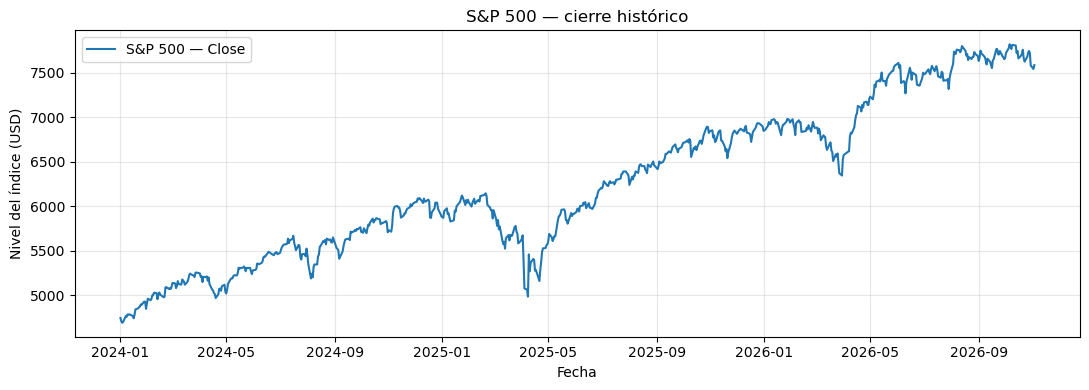

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(prices.date, prices.close.to_numpy(), label="S&P 500 — Close")
ax.set_title("S&P 500 — cierre histórico")
ax.set_xlabel("Fecha")
ax.set_ylabel(f"Nivel del índice ({sp500.currency or 'moneda no indicada'})")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 6. Comprobar otro índice (NASDAQ-100)

Esta prueba confirma que `get_index` no está limitado al S&P 500.

In [7]:
nasdaq = api.get_index(symbol="^NDX", start="2024-01-01", etf_symbol="QQQ")
assert isinstance(nasdaq, Index)
assert nasdaq.symbol == "^NDX"
assert isinstance(nasdaq.price, PriceSeries)
assert len(nasdaq.price.date) > 0
print("NASDAQ-100:", nasdaq.name)
print("Observaciones:", len(nasdaq.price.date))
print("Top holdings disponibles:", nasdaq.constituents is not None)
print("Pesos sectoriales disponibles:", nasdaq.sector_weights is not None)
print("OK: segundo índice descargado")

NASDAQ-100: NASDAQ-100
Observaciones: 713
Top holdings disponibles: True
Pesos sectoriales disponibles: True
OK: segundo índice descargado


## Resultado

Si todas las celdas anteriores terminan sin excepciones, se ha verificado la descarga básica y la estructura de los objetos. **No se ejecutaron pruebas automatizadas offline**: estas celdas consultan Yahoo Finance en tiempo real y dependen de su disponibilidad.